In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

df = pd.read_csv("data/loans_clean.csv", parse_dates=["issue_d"])
print(df.shape)
df.isnull().sum()[df.isnull().sum() > 0]

Matplotlib is building the font cache; this may take a moment.


(1345350, 20)


emp_length    78516
dti             374
revol_util      857
dtype: int64

In [2]:
df["emp_length"] = df["emp_length"].fillna("Unknown")
for c in ["annual_inc","dti","revol_util","delinq_2yrs","open_acc","total_acc"]:
    df[c] = df[c].fillna(df[c].median())

df["annual_inc"] = df["annual_inc"].clip(upper=df["annual_inc"].quantile(0.99))
df["dti"] = df["dti"].clip(upper=df["dti"].quantile(0.99))

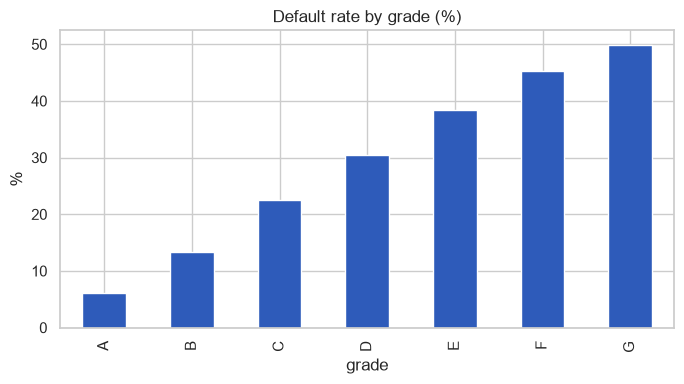

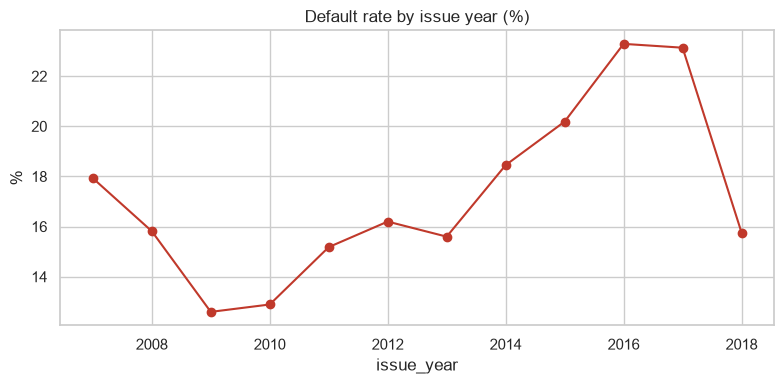

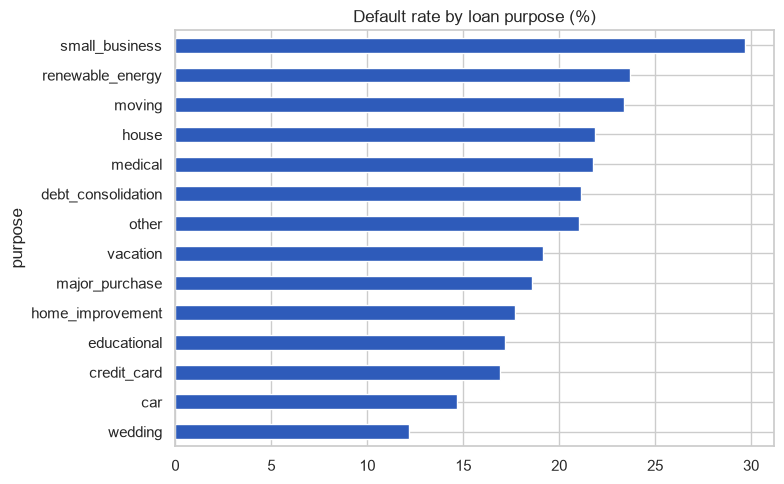

In [3]:
fig, ax = plt.subplots(figsize=(7,4))
(df.groupby("grade")["default"].mean() * 100).plot.bar(ax=ax, color="#2E5BBA")
ax.set_title("Default rate by grade (%)"); ax.set_ylabel("%")
plt.tight_layout(); plt.savefig("images/default_by_grade.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(8,4))
(df.groupby("issue_year")["default"].mean() * 100).plot(ax=ax, marker="o", color="#C0392B")
ax.set_title("Default rate by issue year (%)"); ax.set_ylabel("%")
plt.tight_layout(); plt.savefig("images/default_by_year.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(8,5))
(df.groupby("purpose")["default"].mean().sort_values() * 100).plot.barh(ax=ax, color="#2E5BBA")
ax.set_title("Default rate by loan purpose (%)")
plt.tight_layout(); plt.savefig("images/default_by_purpose.png", dpi=150); plt.show()

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

num = ["loan_amnt","term","int_rate","annual_inc","dti","delinq_2yrs",
       "revol_util","open_acc","total_acc"]
cat = ["home_ownership","verification_status","purpose","emp_length"]

X = pd.get_dummies(df[num + cat], columns=cat, drop_first=True)
y = df["default"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000, class_weight="balanced")
model.fit(X_train_s, y_train)

pred = model.predict(X_test_s)
proba = model.predict_proba(X_test_s)[:, 1]
print(classification_report(y_test, pred))
print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3))

              precision    recall  f1-score   support

           0       0.88      0.67      0.76    215350
           1       0.32      0.62      0.42     53720

    accuracy                           0.66    269070
   macro avg       0.60      0.65      0.59    269070
weighted avg       0.77      0.66      0.69    269070

ROC-AUC: 0.705


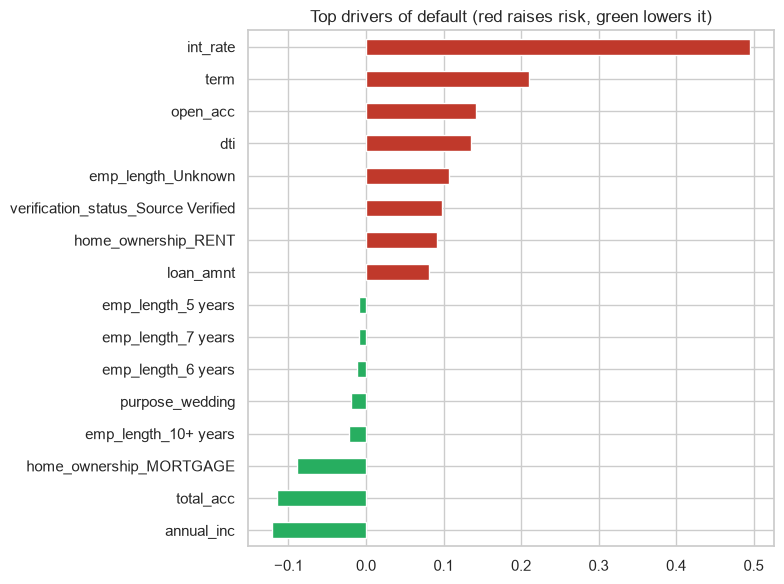

In [5]:
coef = pd.Series(model.coef_[0], index=X.columns).sort_values()
top = pd.concat([coef.head(8), coef.tail(8)])

fig, ax = plt.subplots(figsize=(8,6))
top.plot.barh(ax=ax, color=["#27AE60" if v < 0 else "#C0392B" for v in top])
ax.set_title("Top drivers of default (red raises risk, green lowers it)")
plt.tight_layout(); plt.savefig("images/model_drivers.png", dpi=150); plt.show()

In [2]:
import pandas as pd

df = pd.read_csv("data/loans_clean.csv", parse_dates=["issue_d"])

t = df[["grade","purpose","addr_state","issue_year","term","home_ownership",
        "verification_status","loan_amnt","annual_inc","dti","int_rate","default"]].copy()

t["income_band"] = pd.cut(t["annual_inc"], [0,40000,80000,120000,1e9],
                          labels=["Under 40k","40k-80k","80k-120k","Over 120k"])
t["dti_band"] = pd.cut(t["dti"], [-1,10,20,30,1e9],
                       labels=["Under 10","10-20","20-30","30+"])
t["defaulted_amount"] = t["loan_amnt"] * t["default"]

t.to_csv("dashboard/tableau_data.csv", index=False)
t.shape

(1345350, 15)

In [1]:
import pandas as pd
df = pd.read_csv("data/loans_clean.csv")

g = df.groupby("grade").agg(loans=("default","size"), defaults=("default","sum"))
g["pct_of_loans"] = (g["loans"]/g["loans"].sum()*100).round(1)
g["pct_of_defaults"] = (g["defaults"]/g["defaults"].sum()*100).round(1)
print(g)
print((df.groupby("term")["default"].mean()*100).round(1))

        loans  defaults  pct_of_loans  pct_of_defaults
grade                                                 
A      235095     14206          17.5              5.3
B      392748     52576          29.2             19.6
C      381694     85657          28.4             31.9
D      200966     61067          14.9             22.7
E       93656     36041           7.0             13.4
F       32059     14492           2.4              5.4
G        9132      4560           0.7              1.7
term
36    16.0
60    32.4
Name: default, dtype: float64
